In [154]:
!pip install numpy 


[notice] A new release of pip is available: 24.2 -> 24.3.1
[notice] To update, run: python3 -m pip install --upgrade pip


In [155]:
import numpy as np
import copy
d = 100
m = 10
A = np.random.normal(0, 1, (m,d))
b = np.random.normal(0, 1, m)
initial_x = np.zeros(d)

In [156]:
def f(x,lambdas): 
    error = A@x-b
    error_l2_norm = np.linalg.norm(error)**2  
    regularizer = lambdas * np.linalg.norm(x)**2 
    return error_l2_norm + regularizer 

In [157]:

def coordinate_opt(A,b,lambdas,x,t):
   x_updated = copy.deepcopy(x)
   A_i_th_row = A[:,t] ## select the i-th column 
   residual = b - A @ x_updated + A_i_th_row * x_updated[t] 
   numerator = A_i_th_row@residual ## above
   denominator = A_i_th_row@A_i_th_row + lambdas ## below
   x_updated[t] = numerator/denominator 
   return x_updated 
  

In [158]:
import matplotlib.pyplot as plt
def ridge_regresison_solver(A,b,lambdas,x_init,T=2000): 
    x = copy.deepcopy(x_init)
    counter = 0 
    ans = []
    while (counter < T): 
        t = counter % d  
        x = coordinate_opt(A,b,lambdas,x,t)
        ans.append(f(x,lambdas))
        counter += 1
    return ans

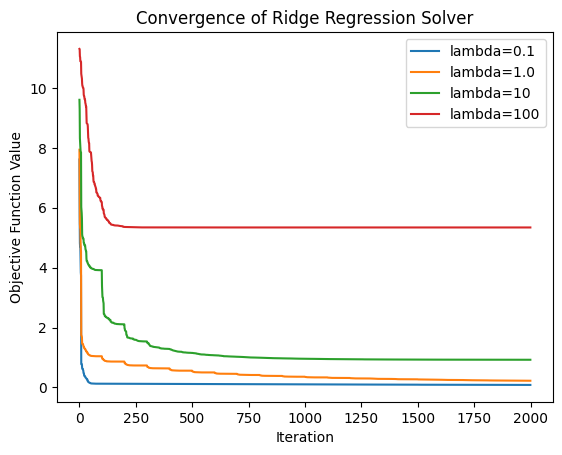

In [159]:
res1 = ridge_regresison_solver(A,b,0.1,initial_x)
res2 = ridge_regresison_solver(A,b,1.0,initial_x)
res3 = ridge_regresison_solver(A,b,10,initial_x)
res4 = ridge_regresison_solver(A,b,100,initial_x)

plt.plot(res1, label='lambda=0.1')
plt.plot(res2, label='lambda=1.0')
plt.plot(res3, label='lambda=10')
plt.plot(res4, label='lambda=100')

plt.xlabel('Iteration')
plt.ylabel('Objective Function Value')
plt.title('Convergence of Ridge Regression Solver')
plt.legend()
plt.savefig('ridge_regression_convergence.png')